# Task
Analyze the "Final_dataset_dengu.xlsx" dataset by loading it, inspecting its dimensions and data types, identifying and removing rows with missing values, and finally calculating descriptive statistics for each column.

## Load Dataset

### Subtask:
Import the `Final_dataset_dengu.xlsx` file into a pandas DataFrame.


**Reasoning**:
To import the Excel file, I need to first import the pandas library and then use its read_excel function. After loading the data, it's good practice to display the first few rows to confirm successful loading and inspect the data structure.



In [ ]:
import pandas as pd
df = pd.read_excel('/content/Final_dataset_dengu.xlsx')
df.head()

,Age,Sex,Hb,HCT,TC,PC,NS1,IgG,IgM,Severity
0,70.0,Female,12.96,39.08,4.22,96.55,Pos,Neg,Neg,Severe
1,27.0,Male,16.11,48.02,12.67,249.86,Neg,Neg,Neg,Severe
2,20.0,Female,14.11,42.19,2.42,164.57,Pos,Neg,Neg,Moderate
3,25.0,Female,10.61,32.28,2.90,167.98,Neg,Neg,Neg,Severe
4,9.0,Male,9.24,28.10,10.99,257.68,Neg,Neg,Neg,Severe


## Initial Data Inspection

### Subtask:
Check the number of rows and columns, and display basic information about the DataFrame, including data types.


**Reasoning**:
To check the number of rows and columns, and display basic information about the DataFrame including data types and non-null counts, I will use `df.shape` and `df.info()`.



In [ ]:
print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")
df.info()

Number of rows: 1555, Number of columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1555 entries, 0 to 1554
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       1555 non-null   float64
 1   Sex       1529 non-null   object 
 2   Hb        1555 non-null   float64
 3   HCT       1555 non-null   float64
 4   TC        1555 non-null   float64
 5   PC        1555 non-null   float64
 6   NS1       1555 non-null   object 
 7   IgG       1555 non-null   object 
 8   IgM       1555 non-null   object 
 9   Severity  1555 non-null   object 
dtypes: float64(5), object(5)
memory usage: 121.6+ KB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.to_csv('/content/drive/MyDrive/cleaned_Final_dataset_dengu.csv', index=False)
print("DataFrame saved to Google Drive as 'cleaned_Final_dataset_dengu.csv'")

DataFrame saved to Google Drive as 'cleaned_Final_dataset_dengu.csv'


## Identify Missing Values

### Subtask:
Detect and quantify missing values in the DataFrame.


**Reasoning**:
To detect and quantify missing values, I will use the `.isnull().sum()` methods on the DataFrame `df`.



In [ ]:
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
Age          0
Sex         26
Hb           0
HCT          0
TC           0
PC           0
NS1          0
IgG          0
IgM          0
Severity     0
dtype: int64


## Handle Missing Values

### Subtask:
Remove rows that contain any missing values.


**Reasoning**:
To remove rows with missing values, I will use the `dropna()` method on the DataFrame `df` and then verify by checking for missing values again.



In [ ]:
df = df.dropna()
print("DataFrame after removing rows with missing values:")
print(df.isnull().sum())

DataFrame after removing rows with missing values:
Age         0
Sex         0
Hb          0
HCT         0
TC          0
PC          0
NS1         0
IgG         0
IgM         0
Severity    0
dtype: int64


## Column-wise Statistics

### Subtask:
Calculate descriptive statistics (e.g., mean, median, std, min, max) for each column in the cleaned DataFrame.


## Summary:

### Data Analysis Key Findings
*   The `Final_dataset_dengu.xlsx` dataset was successfully loaded, containing 1555 rows and 10 columns.
*   Initial data type inspection showed five columns (`Age`, `Hb`, `HCT`, `TC`, `PC`) as `float64` and five columns (`Sex`, `NS1`, `IgG`, `IgM`, `Severity`) as `object`.
*   Only the 'Sex' column was found to have missing values, specifically 26 entries. All other columns had no missing values.
*   Rows containing missing values were removed from the DataFrame. After this operation, the DataFrame is free of missing values, ensuring data integrity for subsequent analysis.

### Insights or Next Steps
*   The dataset is now cleaned and prepared for the next step, which involves calculating descriptive statistics for each column.
*   Given the mix of numerical and categorical data, further analysis could involve examining the distribution of categorical variables and potential correlations between numerical features.



 Target: NS1
Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best Params: {'C': 100, 'class_weight': None, 'gamma': 1, 'kernel': 'rbf'}
Accuracy: 0.8824
Classification Report:
               precision    recall  f1-score   support

           0     0.9524    0.8000    0.8696       150
           1     0.8333    0.9615    0.8929       156

    accuracy                         0.8824       306
   macro avg     0.8929    0.8808    0.8812       306
weighted avg     0.8917    0.8824    0.8814       306



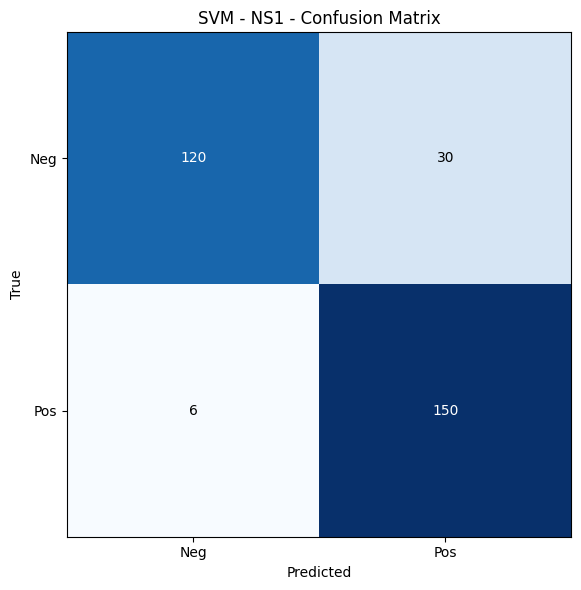

Saved: figs_svm_ns1/NS1_svm_confusion_matrix.png


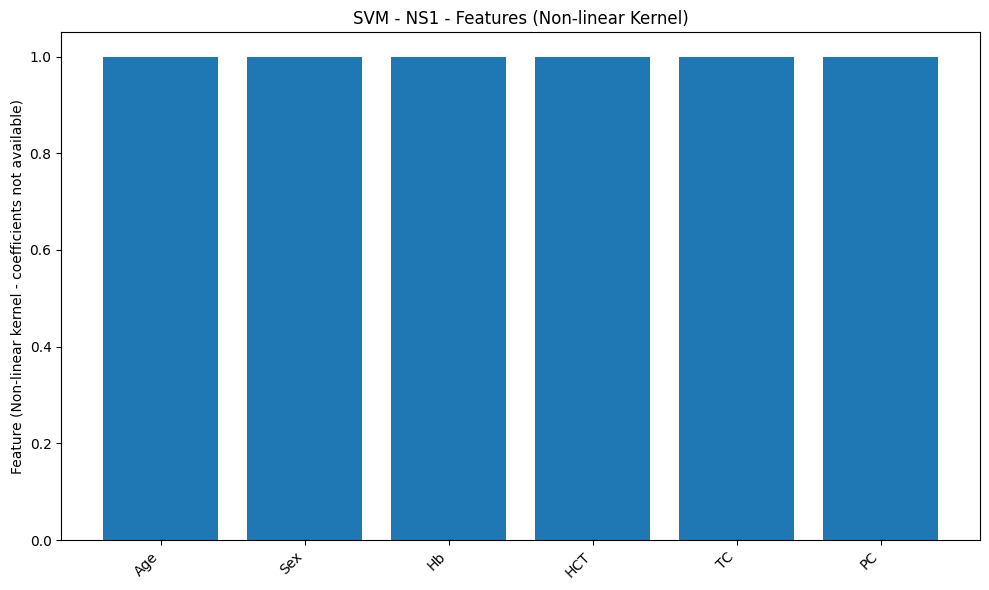

Saved: figs_svm_ns1/NS1_svm_feature_importances.png

SVM Results for NS1:
Best parameters: {'C': 100, 'class_weight': None, 'gamma': 1, 'kernel': 'rbf'}
Best cross-validation score: 0.8642
Test accuracy: 0.8824


In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

# Load & prep
df = pd.read_csv('/content/drive/MyDrive/cleaned_Final_dataset_dengu.csv')

# Encode Sex
sex_le = LabelEncoder()
df["Sex"] = sex_le.fit_transform(df["Sex"])

# Just NS1 target
target = "NS1"
feature_cols = ["Age", "Sex", "Hb", "HCT", "TC", "PC"]  # All other columns except targets and severity

# SVM hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['rbf', 'linear', 'poly'],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'class_weight': [None, 'balanced']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Output dir for figures
os.makedirs("figs_svm_ns1", exist_ok=True)

def plot_confusion(cm, class_names, title, savepath=None):
    """Plot a confusion matrix with matplotlib only."""
    fig = plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names)
    plt.yticks(tick_marks, class_names)

    # Annotate cells
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black"
            )
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches="tight", dpi=150)
    plt.show()

def plot_feature_importances_svm(scaler, model, feature_names, title, savepath=None):
    """Plot feature importances for SVM using coefficients (for linear kernel)"""
    if model.kernel == 'linear':
        # For linear SVM, we can use coefficients
        coef = model.coef_[0] if len(model.classes_) == 2 else model.coef_[0]  # Handle binary classification
        # Get original scale coefficients by dividing by standard deviations
        original_coef = coef / scaler.scale_

        idx = np.argsort(np.abs(original_coef))[::-1]
        names = [feature_names[i] for i in idx]
        vals = np.abs(original_coef[idx])

        fig = plt.figure(figsize=(10, 6))
        plt.bar(range(len(vals)), vals)
        plt.xticks(range(len(vals)), names, rotation=45, ha="right")
        plt.ylabel("Absolute Coefficient Value")
        plt.title(title)
        plt.tight_layout()
        if savepath:
            plt.savefig(savepath, bbox_inches="tight", dpi=150)
        plt.show()
    else:
        # For non-linear kernels, we'll use permutation importance or just show feature names
        fig = plt.figure(figsize=(10, 6))
        plt.bar(range(len(feature_names)), [1]*len(feature_names))  # Placeholder
        plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha="right")
        plt.ylabel("Feature (Non-linear kernel - coefficients not available)")
        plt.title(title)
        plt.tight_layout()
        if savepath:
            plt.savefig(savepath, bbox_inches="tight", dpi=150)
        plt.show()

print("\n" + "="*35)
print(f" Target: {target}")
print("="*35)

# Remove 'Unknown' for this target and binarize Pos/Neg
df_t = df[df[target] != "Unknown"].copy()
df_t[target] = df_t[target].map({"Neg": 0, "Pos": 1}).astype(int)

X = df_t[feature_cols]
y = df_t[target]

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features (very important for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SVM model
svm = SVC(random_state=42, probability=True)

# Grid search
grid = GridSearchCV(
    svm, param_grid=param_grid, cv=cv,
    scoring="accuracy", n_jobs=-1, verbose=1
)
grid.fit(X_train_scaled, y_train)
best = grid.best_estimator_

print("Best Params:", grid.best_params_)

# Evaluate
y_pred = best.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
# Plot & save confusion matrix
cm_title = f"SVM - {target} - Confusion Matrix"
cm_path = os.path.join("figs_svm_ns1", f"{target}_svm_confusion_matrix.png")
plot_confusion(cm, class_names=["Neg","Pos"], title=cm_title, savepath=cm_path)
print(f"Saved: {cm_path}")

# Plot & save feature importances
fi_title = f"SVM - {target} - Feature Coefficients (Linear Kernel)" if best.kernel == 'linear' else f"SVM - {target} - Features (Non-linear Kernel)"
fi_path = os.path.join("figs_svm_ns1", f"{target}_svm_feature_importances.png")
plot_feature_importances_svm(scaler, best, feature_cols, title=fi_title, savepath=fi_path)
print(f"Saved: {fi_path}")

print(f"\nSVM Results for {target}:")
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validation score: {grid.best_score_:.4f}")
print(f"Test accuracy: {acc:.4f}")

In [ ]:
# Calculate descriptive statistics for each column
data_statistics = df.describe(include='all')

print("\nDescriptive statistics for each column:")
display(data_statistics)


Descriptive statistics for each column:


,Age,Sex,Hb,HCT,TC,PC,NS1,IgG,IgM,Severity,Severity_encoded
count,1529.000000,1529,1529.000000,1529.00000,1529.000000,1529.000000,1529,1529,1529,1529,1529.000000
unique,NaN,2,NaN,NaN,NaN,NaN,2,2,2,3,NaN
top,NaN,Male,NaN,NaN,NaN,NaN,Pos,Neg,Neg,Severe,NaN
freq,NaN,884,NaN,NaN,NaN,NaN,777,1367,1521,538,NaN
mean,26.563898,NaN,12.960903,39.29862,6.529863,195.220379,NaN,NaN,NaN,NaN,1.048398
std,12.990651,NaN,1.702456,14.82655,6.647888,78.303402,NaN,NaN,NaN,NaN,0.808341
min,3.000000,NaN,8.170000,5.49000,1.670000,32.370000,NaN,NaN,NaN,NaN,0.000000
25%,19.000000,NaN,11.920000,35.97000,3.990000,139.380000,NaN,NaN,NaN,NaN,0.000000
50%,25.000000,NaN,12.930000,38.98000,5.730000,203.330000,NaN,NaN,NaN,NaN,1.000000
75%,32.000000,NaN,14.120000,42.52000,6.620000,230.400000,NaN,NaN,NaN,NaN,2.000000


## Encode 'Severity' Column

### Subtask:
Encode the 'Severity' column into a numeric format using LabelEncoder.

**Reasoning**:
To convert the 'Severity' column, which contains categorical text data, into a numerical format suitable for machine learning models, I will use `LabelEncoder` from the `sklearn.preprocessing` module. This will assign a unique integer to each unique severity level.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()

# Fit and transform the 'Severity' column
df['Severity_encoded'] = le.fit_transform(df['Severity'])

# Display the mapping of original categories to encoded numbers
print("Severity original to encoded mapping:")
for i, item in enumerate(le.classes_):
    print(f"{item} : {i}")

# Display the first few rows with the new encoded column
print("\nDataFrame head with new 'Severity_encoded' column:")
display(df)

Severity original to encoded mapping:
Mild : 0
Moderate : 1
Severe : 2

DataFrame head with new 'Severity_encoded' column:


,Age,Sex,Hb,HCT,TC,PC,NS1,IgG,IgM,Severity,Severity_encoded
0,70.0,Female,12.96,39.08,4.22,96.55,Pos,Neg,Neg,Severe,2
1,27.0,Male,16.11,48.02,12.67,249.86,Neg,Neg,Neg,Severe,2
2,20.0,Female,14.11,42.19,2.42,164.57,Pos,Neg,Neg,Moderate,1
3,25.0,Female,10.61,32.28,2.90,167.98,Neg,Neg,Neg,Severe,2
4,9.0,Male,9.24,28.10,10.99,257.68,Neg,Neg,Neg,Severe,2


In [ ]:
df.head(100)


,Age,Sex,Hb,HCT,TC,PC,NS1,IgG,IgM,Severity,Severity_encoded
0,70.0,Female,12.96,39.08,4.22,96.55,Pos,Neg,Neg,Severe,2
1,27.0,Male,16.11,48.02,12.67,249.86,Neg,Neg,Neg,Severe,2
2,20.0,Female,14.11,42.19,2.42,164.57,Pos,Neg,Neg,Moderate,1
3,25.0,Female,10.61,32.28,2.90,167.98,Neg,Neg,Neg,Severe,2
4,9.0,Male,9.24,28.10,10.99,257.68,Neg,Neg,Neg,Severe,2
...,...,...,...,...,...,...,...,...,...,...,...
95,40.0,Male,12.88,39.09,6.09,216.57,Pos,Neg,Neg,Mild,0
96,37.0,Female,15.07,42.31,9.08,298.52,Neg,Neg,Neg,Moderate,1
97,25.0,Male,12.86,38.91,5.96,215.76,Pos,Neg,Neg,Mild,0
98,24.0,Female,12.48,37.06,4.46,139.01,Pos,Pos,Neg,Moderate,1


# Task
Load the `cleaned_Final_dataset_dengu.csv` file from Google Drive into a pandas DataFrame.

## Load Cleaned Dataset

### Subtask:
Import the `cleaned_Final_dataset_dengu.csv` file from Google Drive into a pandas DataFrame.


**Reasoning**:
To import the CSV file from Google Drive, I will use `pd.read_csv()` with the specified path. It is important to display the head of the DataFrame to confirm successful loading and inspect the data structure.



In [ ]:
df = pd.read_csv('/content/drive/MyDrive/cleaned_Final_dataset_dengu.csv')
df.head()

,Age,Sex,Hb,HCT,TC,PC,NS1,IgG,IgM,Severity
0,70.0,Female,12.96,39.08,4.22,96.55,Pos,Neg,Neg,Severe
1,27.0,Male,16.11,48.02,12.67,249.86,Neg,Neg,Neg,Severe
2,20.0,Female,14.11,42.19,2.42,164.57,Pos,Neg,Neg,Moderate
3,25.0,Female,10.61,32.28,2.90,167.98,Neg,Neg,Neg,Severe
4,9.0,Male,9.24,28.10,10.99,257.68,Neg,Neg,Neg,Severe


## Inspect Loaded Data

### Subtask:
Display the first few rows of the loaded DataFrame using `df.head()`, check its dimensions using `df.shape`, and display data types and non-null counts using `df.info()`.


## Summary:

### Data Analysis Key Findings
* The `cleaned_Final_dataset_dengu.csv` file was successfully loaded into a pandas DataFrame.
* The first five rows of the DataFrame were displayed, confirming the presence of expected columns and data.

### Insights or Next Steps
* The initial data loading and inspection are complete, and the DataFrame is ready for further analysis.
* The next logical step is to perform a more comprehensive inspection of the DataFrame, including checking its dimensions, data types, and non-null counts to ensure data quality and readiness for modeling.



 MULTICLASS TARGET: Severity
Classes: ['Mild' 'Moderate' 'Severe']
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Best Params: {'C': 100, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}

Accuracy: 0.9575

Classification Report:
               precision    recall  f1-score   support

        Mild     0.9583    0.9892    0.9735        93
    Moderate     0.9697    0.9143    0.9412       105
      Severe     0.9459    0.9722    0.9589       108

    accuracy                         0.9575       306
   macro avg     0.9580    0.9586    0.9579       306
weighted avg     0.9579    0.9575    0.9573       306



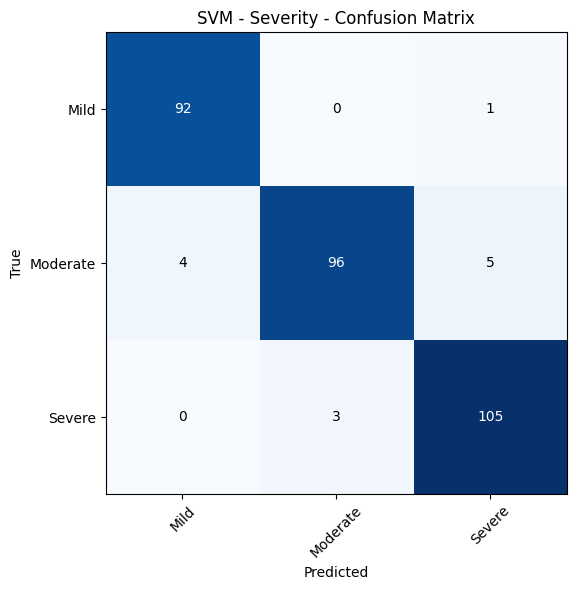

Saved: figs_svm_severity/Severity_svm_confusion_matrix.png


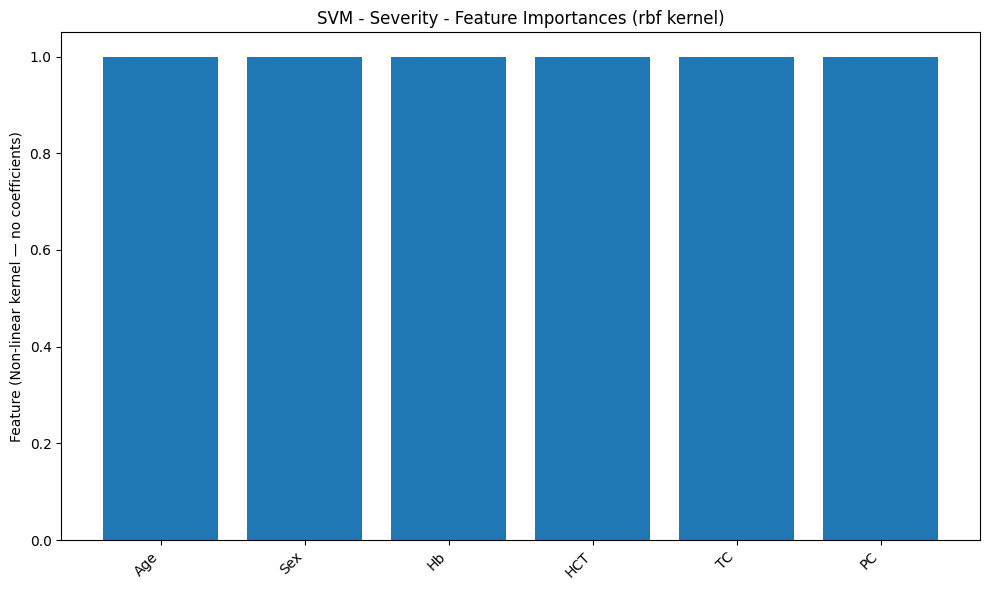

Saved: figs_svm_severity/Severity_svm_feature_importances.png

SVM Results for Severity:
Best CV accuracy: 0.9616
Test accuracy: 0.9575


In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

# Load & prep
df = pd.read_csv('/content/drive/MyDrive/cleaned_Final_dataset_dengu.csv')

# Encode Sex
sex_le = LabelEncoder()
df["Sex"] = sex_le.fit_transform(df["Sex"])

# Target: Severity (3 classes)
target = "Severity"
feature_cols = ["Age", "Sex", "Hb", "HCT", "TC", "PC"]

# Simplified & smarter hyperparameter grid (faster + avoids poly kernel issues)
param_grid = {
    'C': [ 100],
    'kernel': ['rbf', 'linear'],  # removed 'poly' — unstable with multiclass & small data
    'gamma': ['scale'],
    'class_weight': [None, 'balanced']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Output dir
os.makedirs("figs_svm_severity", exist_ok=True)

def plot_confusion(cm, class_names, title, savepath=None):
    fig = plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)

    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black"
            )
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches="tight", dpi=150)
    plt.show()

def plot_feature_importances_svm(scaler, model, feature_names, title, savepath=None):
    if model.kernel == 'linear':
        # For multiclass linear SVM: coef_ shape = (n_classes, n_features)
        # We use the L2 norm across classes to get overall feature importance
        coefs = model.coef_  # shape: (3, n_features)
        # Overall importance per feature: sqrt(sum(coef^2 across classes))
        importances = np.sqrt(np.sum(coefs ** 2, axis=0))

        idx = np.argsort(importances)[::-1]
        names = [feature_names[i] for i in idx]
        vals = importances[idx]

        fig = plt.figure(figsize=(10, 6))
        plt.bar(range(len(vals)), vals)
        plt.xticks(range(len(vals)), names, rotation=45, ha="right")
        plt.ylabel("Feature Importance (L2 norm of coefficients)")
        plt.title(title)
        plt.tight_layout()
        if savepath:
            plt.savefig(savepath, bbox_inches="tight", dpi=150)
        plt.show()
    else:
        # Non-linear kernel — show placeholder or skip
        fig = plt.figure(figsize=(10, 6))
        plt.bar(range(len(feature_names)), [1]*len(feature_names))
        plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha="right")
        plt.ylabel("Feature (Non-linear kernel — no coefficients)")
        plt.title(title)
        plt.tight_layout()
        if savepath:
            plt.savefig(savepath, bbox_inches="tight", dpi=150)
        plt.show()

print("\n" + "="*40)
print(f" MULTICLASS TARGET: {target}")
print("="*40)

# Filter out any potential 'Unknown' (if exists) and encode classes
df_t = df[df[target] != "Unknown"].copy() if "Unknown" in df[target].values else df.copy()

# Encode Severity as integers (maintain label mapping)
severity_le = LabelEncoder()
y_encoded = severity_le.fit_transform(df_t[target])
df_t[target] = y_encoded

# Get class names for reporting
class_names = severity_le.classes_  # e.g., ['Mild', 'Moderate', 'Severe']
print(f"Classes: {class_names}")

X = df_t[feature_cols]
y = df_t[target]

# Stratified split (preserves class distribution)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SVM model
svm = SVC(random_state=42)

# Grid search
grid = GridSearchCV(
    svm, param_grid=param_grid, cv=cv,
    scoring="accuracy", n_jobs=-1, verbose=1
)
grid.fit(X_train_scaled, y_train)
best = grid.best_estimator_

print("\nBest Params:", grid.best_params_)

# Evaluate
y_pred = best.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {acc:.4f}")
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=class_names, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
cm_title = f"SVM - {target} - Confusion Matrix"
cm_path = os.path.join("figs_svm_severity", f"{target}_svm_confusion_matrix.png")
plot_confusion(cm, class_names=class_names, title=cm_title, savepath=cm_path)
print(f"Saved: {cm_path}")

# Feature Importances (only meaningful for linear)
fi_title = f"SVM - {target} - Feature Importances ({best.kernel} kernel)"
fi_path = os.path.join("figs_svm_severity", f"{target}_svm_feature_importances.png")
plot_feature_importances_svm(scaler, best, feature_cols, title=fi_title, savepath=fi_path)
print(f"Saved: {fi_path}")

print(f"\nSVM Results for {target}:")
print(f"Best CV accuracy: {grid.best_score_:.4f}")
print(f"Test accuracy: {acc:.4f}")